In [1]:
import os, sys
from pathlib import Path
# Chạy notebook từ thư mục bất kỳ: tìm gốc dự án (thư mục chứa data/) rồi nạp mã nguồn trong rule_engine/.
ROOT = Path.cwd()
while not (ROOT / 'data').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'rule_engine'))
os.chdir(ROOT)

# Phân tích thăm dò dữ liệu (EDA) — Tập hợp đồng lao động mẫu

Mục tiêu: xác nhận tập hợp đồng tự tạo đủ điều kiện làm tập kiểm thử cho rule engine. Ba nội dung kiểm tra: (1) tính chính xác của bước phân tách Điều; (2) độ phủ của từng loại điều khoản và của bước trích xuất đặc trưng; (3) phân bố giá trị định lượng so với ngưỡng luật, cùng sự hiện diện của hợp đồng hợp lệ để đo dương tính giả.

In [2]:
import re
import math
from pathlib import Path
from dataclasses import asdict

import pandas as pd
import matplotlib.pyplot as plt

from ingest import process_batch

# bảng màu dùng chung cho mọi chart
BLUE, RED, INK, MUTED, GRID, SURFACE = "#2a78d6", "#d03b3b", "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [3]:
clauses = process_batch(Path("data/contracts"))
df = pd.DataFrame([asdict(c) for c in clauses])
df["so_tu"] = df["text"].str.split().str.len()
df.head()

,contract_id,dieu_so,tieu_de,text,so_tu
0,HD_001,1,CÔNG VIỆC VÀ ĐỊA ĐIỂM LÀM VIỆC,Người lao động làm việc vị trí Kế toán viên; n...,30
1,HD_001,2,LOẠI VÀ THỜI HẠN HỢP ĐỒNG,"Loại hợp đồng: không xác định thời hạn, có hiệ...",14
2,HD_001,3,"THỜI GIỜ LÀM VIỆC, NGHỈ NGƠI","Thời giờ làm việc 08 giờ/ngày, 48 giờ/tuần, ng...",34
3,HD_001,4,LƯƠNG VÀ PHỤ CẤP,Mức lương theo công việc: 9.000.000 đồng/tháng...,19
4,HD_001,5,HÌNH THỨC VÀ KỲ HẠN TRẢ LƯƠNG,"Trả lương bằng chuyển khoản, 01 lần/tháng vào ...",25


## 1. Kiểm tra cấu trúc phân tách

Thống kê số Điều trên mỗi hợp đồng và độ dài điều khoản, nhằm phát hiện trường hợp phân tách sai.

In [4]:
n_hd = df["contract_id"].nunique()
print(f"{len(df)} điều khoản / {n_hd} hợp đồng — trung bình {len(df)/n_hd:.2f} Điều/HĐ")
print("\nSố Điều mỗi HĐ:")
print(df.groupby("contract_id").size().value_counts().sort_index().to_string())
print("\nĐộ dài điều khoản (số từ):")
print(df["so_tu"].describe().round(1).to_string())

593 điều khoản / 50 hợp đồng — trung bình 11.86 Điều/HĐ

Số Điều mỗi HĐ:
11     7
12    43

Độ dài điều khoản (số từ):
count    593.0
mean      31.7
std       10.9
min       13.0
25%       22.0
50%       32.0
75%       37.0
max       67.0


**Diễn giải.** Nếu một hợp đồng có số Điều lệch hẳn so với phần còn lại, hoặc độ dài (số từ) quá lớn (nhiều Điều bị gộp) hoặc quá nhỏ (nhận nhầm dòng không phải tiêu đề), cần hiệu chỉnh biểu thức `DIEU_PATTERN` trong `ingest.py`.

## 2. Độ phủ điều khoản

Tỉ lệ hợp đồng chứa mỗi loại điều khoản. Loại điều khoản vắng mặt ở nhiều hợp đồng sẽ hạn chế khả năng đánh giá rule tương ứng.

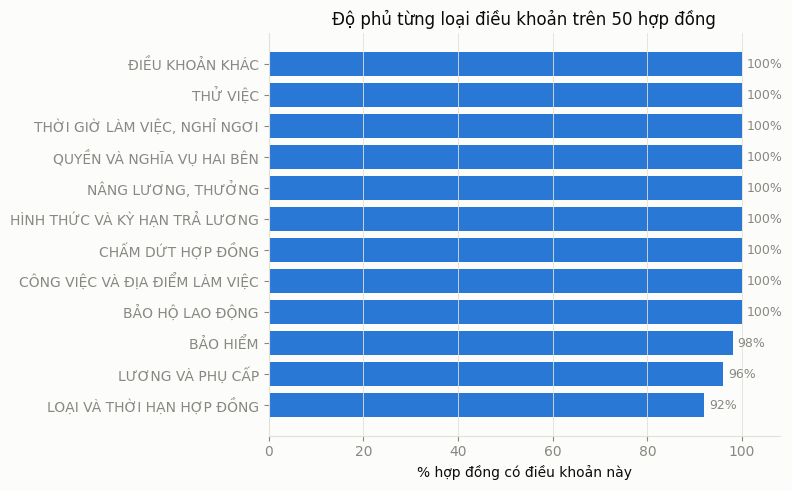

In [5]:
cover = (df.groupby("tieu_de")["contract_id"].nunique() / n_hd * 100).sort_values()
lech = cover[cover < 100]

if len(lech) < 2:
    print(f"{len(cover) - len(lech)}/{len(cover)} loại điều khoản có mặt ở cả {n_hd} HĐ → không cần vẽ.")
    if len(lech):
        print("Không đủ 100%: " + ", ".join(f"{k} ({v:.0f}%)" for k, v in lech.items()))
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(cover.index, cover.values, color=BLUE)
    for y, v in enumerate(cover.values):
        ax.text(v + 1, y, f"{v:.0f}%", va="center", color=MUTED, fontsize=9)
    ax.set_xlim(0, 108)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("% hợp đồng có điều khoản này")
    ax.set_title(f"Độ phủ từng loại điều khoản trên {n_hd} hợp đồng")
    fig.tight_layout()
    plt.show()

## 3. Trích xuất đặc trưng định lượng

Áp dụng tập biểu thức chính quy (dùng cho rule engine) để trích các trường số, đồng thời kiểm tra độ phủ của từng biểu thức.

In [6]:
FIELDS = {
    "luong_thang":    r"([\d.]{7,})\s*đồng/tháng",
    "gio_tuan":       r"(\d{1,2})\s*giờ/tuần",
    "gio_ngay":       r"(\d{1,2})\s*giờ/ngày",
    "lam_them_thang": r"(\d{1,3})\s*giờ/tháng",
    "thu_viec_ngay":  r"thử việc\s+(\d{1,3})\s*ngày",
    "thu_viec_pct":   r"(\d{2,3})\s*%\s*mức lương",
}

def max_num(text, pattern):
    """Lấy giá trị lớn nhất khớp mẫu, tránh nhận nhầm phụ cấp thay cho lương."""
    vals = [int(x.replace(".", "")) for x in re.findall(pattern, text, re.IGNORECASE)]
    return max(vals) if vals else None

by_hd = df.groupby("contract_id")["text"].apply(" ".join)
num = pd.DataFrame({k: by_hd.map(lambda t, p=p: max_num(t, p)) for k, p in FIELDS.items()})

print("Độ phủ trích xuất:")
print(num.notna().sum().to_frame("số HĐ")
      .assign(**{"%": lambda d: (d["số HĐ"] / n_hd * 100).round(0)}).to_string())
num.describe().round(0)

Độ phủ trích xuất:
                số HĐ     %
luong_thang        38  76.0
gio_tuan           42  84.0
gio_ngay           42  84.0
lam_them_thang     43  86.0
thu_viec_ngay      43  86.0
thu_viec_pct        0   0.0


,luong_thang,gio_tuan,gio_ngay,lam_them_thang,thu_viec_ngay
count,38.0,42.0,42.0,43.0,43.0
mean,12763158.0,49.0,8.0,43.0,54.0
std,3927961.0,3.0,0.0,10.0,35.0
min,4000000.0,48.0,8.0,40.0,30.0
25%,10000000.0,48.0,8.0,40.0,30.0
50%,12000000.0,48.0,8.0,40.0,30.0
75%,15000000.0,48.0,8.0,40.0,60.0
max,18000000.0,60.0,10.0,80.0,120.0


**Diễn giải.** Trường có độ phủ thấp hơn kỳ vọng cho thấy biểu thức chưa bao quát hết các cách diễn đạt trong hợp đồng; cần bổ sung biến thể và chạy lại. Riêng các trường thử việc có độ phủ thấp là hợp lý khi một phần hợp đồng không chứa điều khoản thử việc.

## 4. So sánh giá trị với ngưỡng luật

Phân bố giá trị thực trong hợp đồng, đối chiếu với ngưỡng quy định (vạch đỏ). Số hợp đồng nằm ngoài ngưỡng tương ứng với số vi phạm định lượng dự kiến.

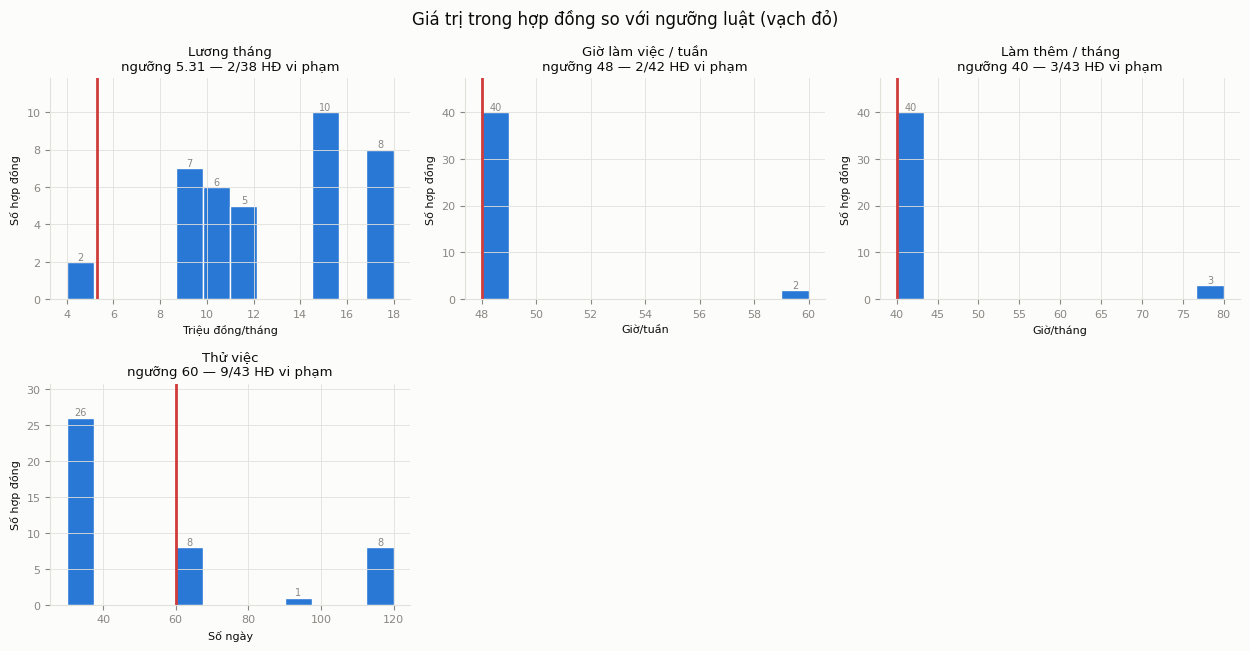

In [7]:
CHECKS = [  # khớp config/thresholds.yaml — thêm cột đơn vị trục hoành (cuối)
    ("luong_thang",    5_310_000, "min", "Lương tháng",        1e6, "Triệu đồng/tháng"),
    ("gio_tuan",       48,        "max", "Giờ làm việc / tuần", 1,  "Giờ/tuần"),
    ("lam_them_thang", 40,        "max", "Làm thêm / tháng",    1,  "Giờ/tháng"),
    ("thu_viec_ngay",  60,        "max", "Thử việc",            1,  "Số ngày"),
    ("thu_viec_pct",   85,        "min", "Lương thử việc",      1,  "% lương chính thức"),
]

avail = [c for c in CHECKS if num[c[0]].notna().any()]
ncol = min(3, len(avail))
nrow = math.ceil(len(avail) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.3 * nrow))
axes = list(axes.flat) if len(avail) > 1 else [axes]

vi_pham = pd.DataFrame(index=num.index)
for ax, (col, thr, kind, title, scale, xlabel) in zip(axes, avail):
    s = num[col].dropna()
    bad = (s < thr) if kind == "min" else (s > thr)
    vi_pham[col] = bad.reindex(num.index)

    counts, edges, patches = ax.hist(s / scale, bins=12, color=BLUE, edgecolor=SURFACE)
    for cnt, p in zip(counts, patches):            # ghi số lên đỉnh mỗi cột
        if cnt > 0:
            ax.text(p.get_x() + p.get_width()/2, cnt, f"{int(cnt)}",
                    ha="center", va="bottom", fontsize=7, color=MUTED)

    ax.axvline(thr / scale, color=RED, linewidth=2)
    ax.set_ylim(0, counts.max() * 1.18)            # chừa khoảng trống cho nhãn
    ax.set_title(f"{title}\nngưỡng {thr/scale:g} — {bad.sum()}/{len(s)} HĐ vi phạm", fontsize=9.5)
    ax.set_xlabel(xlabel, fontsize=8)
    ax.set_ylabel("Số hợp đồng", fontsize=8)
    ax.tick_params(labelsize=8)
for ax in axes[len(avail):]:
    ax.remove()

fig.suptitle("Giá trị trong hợp đồng so với ngưỡng luật (vạch đỏ)", fontsize=12)
fig.tight_layout()
plt.show()

## 5. Số vi phạm định lượng trên mỗi hợp đồng

Phân bố số ngưỡng bị vượt trong từng hợp đồng.

Số hợp đồng không vượt ngưỡng nào: 36/50


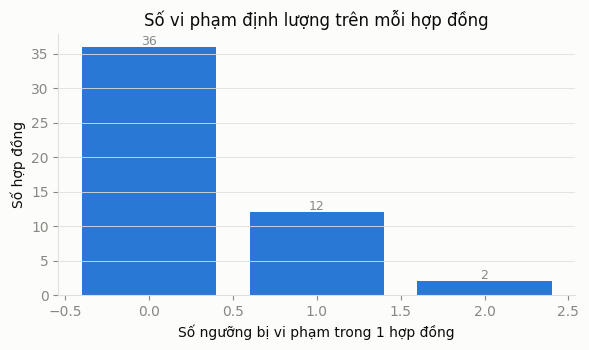

In [8]:
so_loi = vi_pham.fillna(False).sum(axis=1).astype(int)
print(f"Số hợp đồng không vượt ngưỡng nào: {(so_loi == 0).sum()}/{n_hd}")

vc = so_loi.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(vc.index, vc.values, color=BLUE)
for x, y in vc.items():
    ax.text(x, y + 0.3, str(y), ha="center", color=MUTED, fontsize=9)
ax.set_xlabel("Số ngưỡng bị vi phạm trong 1 hợp đồng")
ax.set_ylabel("Số hợp đồng")
ax.set_title("Số vi phạm định lượng trên mỗi hợp đồng")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Diễn giải.** Nếu không có hợp đồng nào ở mức 0 vi phạm, tập kiểm thử chưa cho phép đo dương tính giả; cần bổ sung hợp đồng hoàn toàn hợp lệ trước khi đánh giá rule engine.

## 6. Xuất bảng tổng hợp

Lưu bảng đặc trưng và số vi phạm định lượng theo hợp đồng để phục vụ bước đánh giá.

In [9]:
ket_qua = num.copy()
ket_qua["so_loi_dinh_luong"] = so_loi
ket_qua.to_csv("data/eda_summary.csv", encoding="utf-8-sig")
print("Đã lưu data/eda_summary.csv")
ket_qua.head()

Đã lưu data/eda_summary.csv


,luong_thang,gio_tuan,gio_ngay,lam_them_thang,thu_viec_ngay,thu_viec_pct,so_loi_dinh_luong
contract_id,,,,,,,
HD_001,9000000.0,48.0,8.0,40.0,30.0,None,0
HD_002,18000000.0,48.0,8.0,40.0,30.0,None,0
HD_003,10000000.0,48.0,8.0,40.0,30.0,None,0
HD_004,9000000.0,48.0,8.0,40.0,30.0,None,0
HD_005,12000000.0,48.0,8.0,40.0,30.0,None,0
